# 07 Do style matchups predict outcomes beyond Elo?

Leak-free, time-split evaluation (`src/elo.py`, `src/matchups.py`, `docs/matchups.md`):

- **Elo:** fight-by-fight ratings from all UFC fights since 1994. K = 80, chosen on 2005–2018 fights only.
- **Style axes:** fitted on profiles built **as of 2019-01-01** and frozen, aligned to the four named axes. For every fight, both
  fighters' profiles are built as of the fight date (earlier fights only) and transformed with that frozen model.
- **Train:** decisive fights 2006–2018. **Test:** decisive fights from 2019-01-01 to 2026-08-08. Inclusion: both fighters have ≥ 3 prior
  UFC fights since 2000 (≥ 5 also reported). Draws and no contests are excluded from the outcome models.
- **Models** (logistic, no intercept, antisymmetric features, so P(A beats B) = 1 − P(B beats A)):
  1. Elo difference
  2. + differences in the four axis scores
  3. + the six antisymmetric interactions a_i·b_j − a_j·b_i
- **Regularization:** L2 on the style terms only, never on Elo. The penalty on the axis differences is tuned for model 2. Model 3 keeps
  that and tunes a separate penalty on the interactions. Tuning uses time-based validation inside the training period (fit on 2006–15,
  validate on 2016–18).

**Rule:** an effect is claimed only if it holds up on the 2019+ test set.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import elo
import features as F
import matchups as M
import style_axes as A

pd.set_option("display.width", 220, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
NAMES = {f"d_{k}": f"Δ {v}" for k, v in A.AXIS_NAMES.items()}
NAMES.update({f"x_{M.AXES[i]}_{M.AXES[j]}": f"{A.AXIS_NAMES[M.AXES[i]]} × {A.AXIS_NAMES[M.AXES[j]]}" for i, j in M.PAIRS})
NAMES["elo_diff"] = "Elo difference (per 100 points)"
data = M.build_dataset()
print(data.groupby("set").agg(fights=("y", "size"), first=("event_date", "min"), last=("event_date", "max")))

       fights       first        last
set                                  
test     3047  2019-01-19  2026-08-08
train    3172  2006-01-16  2018-12-29


## 1. Elo: choosing K on pre-test fights

k,8,12,16,20,24,28,32,40,48,56,64,80,96,128
log_loss,0.6896,0.6881,0.6868,0.6856,0.6845,0.6836,0.6827,0.6813,0.6802,0.6793,0.6788,0.6782,0.6785,0.6813
brier,0.2482,0.2475,0.2468,0.2463,0.2457,0.2453,0.2449,0.2442,0.2436,0.2432,0.2429,0.2426,0.2427,0.2436
fights,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000


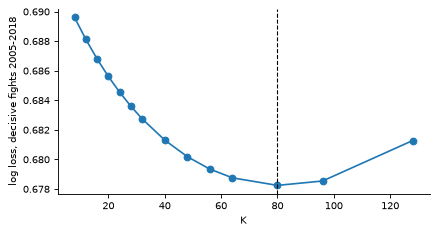

chosen K = 80 (minimum of the grid; flat from 64 to 96). Coin-flip log loss = 0.6931.


In [2]:
kt = elo.tune_k(elo.load_ufc_fights())
display(kt.round(4).T)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(kt.index, kt["log_loss"], marker="o"); ax.axvline(elo.ELO_K, color="k", ls="--", lw=1)
ax.set_xlabel("K"); ax.set_ylabel("log loss, decisive fights 2005-2018"); plt.show()
print(f"chosen K = {elo.ELO_K:g} (minimum of the grid; flat from 64 to 96). Coin-flip log loss = {np.log(2):.4f}.")

## 2. The frozen 2019 style axes

Loadings of the axes fitted on profiles as of 2019-01-01, and their congruence with the full-data axes in `docs/style_axes.md`.

In [3]:
ax19 = M.frozen_axes()
full = A.StyleAxes.load(A.MODEL_DIR / "style_axes_m4.joblib")
display(ax19.loadings.rename(columns=A.AXIS_NAMES).round(2))
cong = [float(full.loadings.iloc[:, j] @ ax19.loadings.iloc[:, j] / np.linalg.norm(full.loadings.iloc[:, j]) / np.linalg.norm(ax19.loadings.iloc[:, j])) for j in range(4)]
print("fitted on", ax19.metadata["n_fighters"], "eligible fighters as of 2019-01-01; congruence with full-data axes:",
      dict(zip(A.AXIS_NAMES.values(), np.round(cong, 3))))

,grappler vs. volume striker,clinch and body work,submission hunting,leg kicking
pos_clinch,0.25,0.77,0.01,0.05
pos_ground,0.77,0.07,0.25,-0.07
tgt_body,-0.12,0.85,0.03,0.11
tgt_leg,-0.07,0.09,-0.07,0.95
td_att_per15,0.85,-0.08,-0.00,-0.00
ctrl_share,0.93,0.08,0.10,-0.06
sub_att_per15,0.07,0.00,0.88,-0.15
pace,-0.44,-0.12,-0.57,-0.32


fitted on 706 eligible fighters as of 2019-01-01; congruence with full-data axes: {'grappler vs. volume striker': np.float64(0.997), 'clinch and body work': np.float64(0.997), 'submission hunting': np.float64(0.992), 'leg kicking': np.float64(0.989)}


## 3. Model comparison on the 2019+ test set

In [4]:
res = {mp: M.evaluate(data, mp, n_boot=2000) for mp in (3, 5)}
for mp, r in res.items():
    print(f"\n=== both fighters with >= {mp} prior UFC fights: train {r['n_train']:,} fights, test {r['n_test']:,} fights ===")
    m = r["metrics"].copy()
    m["log loss [95% CI]"] = [f"{a:.4f} [{b:.4f}, {c:.4f}]" for a, b, c in zip(m.log_loss, m.ll_lo, m.ll_hi)]
    m["Brier [95% CI]"] = [f"{a:.4f} [{b:.4f}, {c:.4f}]" for a, b, c in zip(m.brier, m.brier_lo, m.brier_hi)]
    display(m[["log loss [95% CI]", "Brier [95% CI]", "accuracy"]])
    v = r["vs_elo"].copy()
    v["Δ log loss vs Elo [95% CI]"] = [f"{a:+.4f} [{b:+.4f}, {c:+.4f}]" for a, b, c in zip(v.d_log_loss, v.dll_lo, v.dll_hi)]
    v["Δ Brier vs Elo [95% CI]"] = [f"{a:+.4f} [{b:+.4f}, {c:+.4f}]" for a, b, c in zip(v.d_brier, v.dbr_lo, v.dbr_hi)]
    v["P(better than Elo)"] = v["p_better"].round(3)
    display(v[["Δ log loss vs Elo [95% CI]", "Δ Brier vs Elo [95% CI]", "P(better than Elo)"]])
    print("chosen penalties:", {k: f["lambda"] for k, f in r["fits"].items()},
          "| max |P(A>B) + P(B>A) - 1| after swapping fighters:", max(f["max_swap_error"] for f in r["fits"].values()))


=== both fighters with >= 3 prior UFC fights: train 1,772 fights, test 2,015 fights ===


,log loss [95% CI],Brier [95% CI],accuracy
model,,,
elo,"0.6819 [0.6749, 0.6889]","0.2445 [0.2411, 0.2479]",0.5499
elo+style,"0.6815 [0.6739, 0.6890]","0.2443 [0.2407, 0.2480]",0.5529
elo+inter,"0.6815 [0.6739, 0.6890]","0.2443 [0.2407, 0.2480]",0.5524
raw_elo,"0.6842 [0.6749, 0.6936]","0.2456 [0.2412, 0.2501]",0.5499


,Δ log loss vs Elo [95% CI],Δ Brier vs Elo [95% CI],P(better than Elo)
model,,,
elo+style,"-0.0004 [-0.0032, +0.0025]","-0.0002 [-0.0016, +0.0012]",0.600
elo+inter,"-0.0003 [-0.0032, +0.0025]","-0.0002 [-0.0016, +0.0012]",0.597


chosen penalties: {'elo': 0.0, 'elo+style': 10.0, 'elo+inter': 100000.0} | max |P(A>B) + P(B>A) - 1| after swapping fighters: 2.220446049250313e-16

=== both fighters with >= 5 prior UFC fights: train 1,074 fights, test 1,392 fights ===


,log loss [95% CI],Brier [95% CI],accuracy
model,,,
elo,"0.6793 [0.6702, 0.6886]","0.2433 [0.2389, 0.2478]",0.5532
elo+style,"0.6834 [0.6737, 0.6932]","0.2452 [0.2405, 0.2500]",0.5510
elo+inter,"0.6834 [0.6737, 0.6932]","0.2452 [0.2405, 0.2500]",0.5517
raw_elo,"0.6809 [0.6692, 0.6929]","0.2441 [0.2386, 0.2498]",0.5532


,Δ log loss vs Elo [95% CI],Δ Brier vs Elo [95% CI],P(better than Elo)
model,,,
elo+style,"+0.0041 [-0.0003, +0.0081]","+0.0019 [-0.0002, +0.0039]",0.035
elo+inter,"+0.0041 [-0.0003, +0.0082]","+0.0019 [-0.0002, +0.0039]",0.034


chosen penalties: {'elo': 0.0, 'elo+style': 3.0, 'elo+inter': 100000.0} | max |P(A>B) + P(B>A) - 1| after swapping fighters: 2.220446049250313e-16


`raw_elo` is the Elo expected score used directly. The `elo` model refits its slope on the training fights. Negative Δ means better
than Elo. The intervals are paired bootstraps over test fights (2,000 resamples).

### Regularization: what validation chose

Validation log loss (2016–18) against the penalty. For the interaction model the penalty applies to the interactions only.

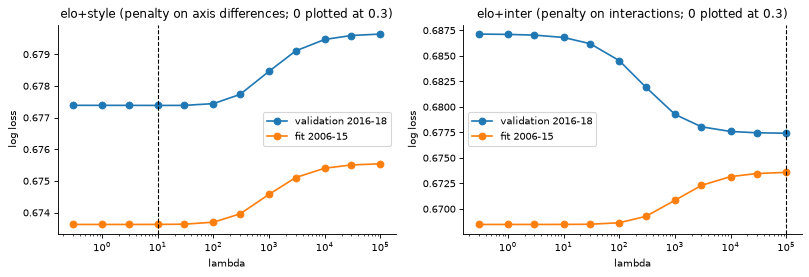

elo        unregularized: train log loss 0.6771, test 0.6819
elo+style  unregularized: train log loss 0.6749, test 0.6815
elo+inter  unregularized: train log loss 0.6731, test 0.6837


In [5]:
r = res[3]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for a, m in zip(axes, ["elo+style", "elo+inter"]):
    t = r["tuning"][m]
    x = np.where(t.index == 0, 0.3, t.index)
    a.semilogx(x, t["val_log_loss"], marker="o", label="validation 2016-18")
    a.semilogx(x, t["fit_log_loss"], marker="o", label="fit 2006-15")
    a.axvline(r["fits"][m]["lambda"] if r["fits"][m]["lambda"] > 0 else 0.3, color="k", ls="--", lw=1)
    a.set_title(f"{m} (penalty on {'axis differences' if m == 'elo+style' else 'interactions'}; 0 plotted at 0.3)")
    a.set_xlabel("lambda"); a.set_ylabel("log loss"); a.legend()
plt.show()
tr, te = r["train"], r["test"]
for m in M.MODELS:
    X, _, _ = M.design(tr, m); Xt, _, _ = M.design(te, m)
    b = M.fit_logistic(X, tr["y"].to_numpy(), 0.0)
    print(f"{m:10s} unregularized: train log loss {M.log_loss(M.predict(X, b), tr['y'].to_numpy()).mean():.4f}, "
          f"test {M.log_loss(M.predict(Xt, b), te['y'].to_numpy()).mean():.4f}")

The unregularized interaction model fits the training fights best and the test fights **worst** (worse than Elo alone): it overfits.
Validation keeps improving as the interaction penalty grows, so the tuned model shrinks the interactions to essentially zero and
ends up identical to the axis-difference model.

## 4. Calibration (test set, ≥ 3 prior fights)

Predicted P(A wins), in 10 equal-count bins, against the observed win rate. A and B are randomly oriented, so predictions span both sides of 0.5.

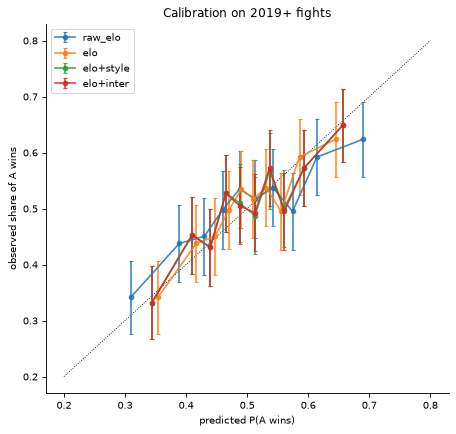

In [6]:
yt = res[3]["test"]["y"].to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0.2, 0.8], [0.2, 0.8], color="k", lw=0.8, ls=":")
for m in ["raw_elo"] + M.MODELS:
    p = res[3]["pred"][m]
    bins = pd.qcut(p, 10, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": yt}).groupby(bins, observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    se = np.sqrt(g["y"] * (1 - g["y"]) / g["n"])
    ax.errorbar(g["p"], g["y"], yerr=1.96 * se, marker="o", ms=4, capsize=2, label=m, alpha=0.85)
ax.set_xlabel("predicted P(A wins)"); ax.set_ylabel("observed share of A wins"); ax.set_title("Calibration on 2019+ fights")
ax.legend(); plt.show()

## 5. Style coefficients with confidence intervals

Logistic coefficients: the change in log-odds of A winning per 1 SD difference on an axis, or per unit of the interaction term.
Elo is per 100 points. Two views:

- **Fitted models (training period, tuned penalties):** the coefficients actually used for the test predictions, with bootstrap CIs
  (500 resamples of training fights, same penalties).
- **Replication check (no penalty):** the same specification estimated separately on the training period and on the test period.
  An effect "holds up" only if it has the same sign and a CI excluding 0 in both, **and** using it improves test predictions (section 3).

In [7]:
tr, te = res[3]["train"], res[3]["test"]
fits = res[3]["fits"]
tables = {}
for m in ["elo+style", "elo+inter"]:
    tables[m] = M.coefficient_cis(tr, m, fits[m]["penalty"].to_numpy(), n_boot=500).rename(index=NAMES)
    print(f"{m}: fitted on 2006-18 with the tuned penalties"); display(tables[m].round(3))
rep = pd.concat({"train 2006-18": M.coefficient_cis(tr, "elo+inter", 0.0, n_boot=500),
                 "test 2019+": M.coefficient_cis(te, "elo+inter", 0.0, n_boot=500)}, axis=1)
rep.index = [NAMES[i] for i in rep.index]
sig = lambda s: (s["lo"] > 0) | (s["hi"] < 0)
rep[("", "replicates")] = sig(rep["train 2006-18"]) & sig(rep["test 2019+"]) & (np.sign(rep[("train 2006-18", "estimate")]) == np.sign(rep[("test 2019+", "estimate")]))
print("Replication check, unpenalized elo + differences + interactions:"); display(rep.round(3))

elo+style: fitted on 2006-18 with the tuned penalties


,estimate,lo,hi
Elo difference (per 100 points),0.417,0.290,0.532
Δ grappler vs. volume striker,0.069,-0.013,0.142
Δ clinch and body work,-0.021,-0.092,0.043
Δ submission hunting,-0.069,-0.144,0.009
Δ leg kicking,-0.021,-0.085,0.047


elo+inter: fitted on 2006-18 with the tuned penalties


,estimate,lo,hi
Elo difference (per 100 points),0.417,0.290,0.532
Δ grappler vs. volume striker,0.068,-0.013,0.142
Δ clinch and body work,-0.022,-0.092,0.043
Δ submission hunting,-0.069,-0.144,0.009
Δ leg kicking,-0.021,-0.085,0.048
grappler vs. volume striker × clinch and body work,0.000,-0.000,0.001
grappler vs. volume striker × submission hunting,-0.000,-0.001,0.000
grappler vs. volume striker × leg kicking,-0.000,-0.001,0.000
clinch and body work × submission hunting,-0.000,-0.001,0.000
clinch and body work × leg kicking,-0.000,-0.001,0.000


Replication check, unpenalized elo + differences + interactions:


train 2006-18               test 2019+                         
                                                        estimate     lo     hi   estimate     lo     hi replicates
Elo difference (per 100 points)                            0.416  0.292  0.532      0.346  0.221  0.470       True
Δ grappler vs. volume striker                              0.070 -0.016  0.148      0.164  0.093  0.235      False
Δ clinch and body work                                    -0.028 -0.107  0.039      0.002 -0.064  0.073      False
Δ submission hunting                                      -0.071 -0.151  0.017      0.042 -0.026  0.117      False
Δ leg kicking                                             -0.013 -0.080  0.065      0.028 -0.038  0.093      False
grappler vs. volume striker × clinch and body work         0.052 -0.014  0.118      0.037 -0.032  0.107      False
grappler vs. volume striker × submission hunting          -0.020 -0.093  0.053     -0.010 -0.072  0.050      False
grappler vs. volume striker × leg kicking                 -0.037 -0.099  0.027      0.021 -0.046  0.089      False
clinch and body work × submission hunting                 -0.020 -0.093  0.044      0.007 -0.055  0.070      False
clinch and body work × leg kicking                        -0.032 -0.103  0.033     -0.063 -0.133  0.005      False
submission hunting × leg kicking                          -0.035 -0.104  0.032      0.065 -0.003  0.134      False

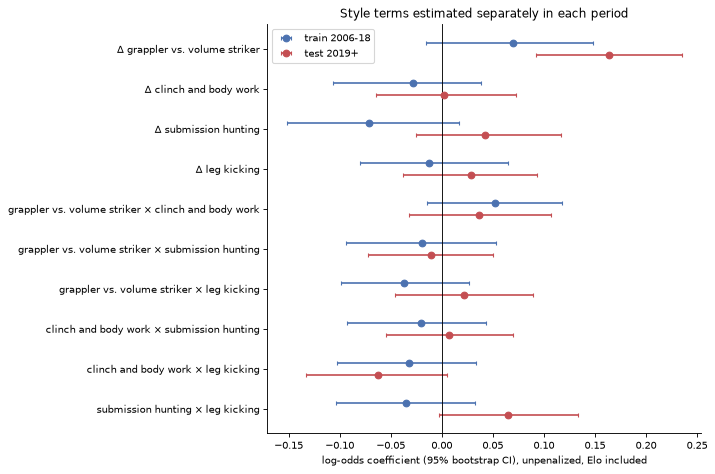

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
terms = [t for t in rep.index if not t.startswith("Elo")]
yy = np.arange(len(terms))
for k, (period, off, col) in enumerate([("train 2006-18", -0.15, "#4C72B0"), ("test 2019+", 0.15, "#C44E52")]):
    e = rep.loc[terms, (period, "estimate")]; lo = rep.loc[terms, (period, "lo")]; hi = rep.loc[terms, (period, "hi")]
    ax.errorbar(e, yy + off, xerr=[e - lo, hi - e], fmt="o", color=col, capsize=2, label=period)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy, terms); ax.invert_yaxis()
ax.set_xlabel("log-odds coefficient (95% bootstrap CI), unpenalized, Elo included")
ax.set_title("Style terms estimated separately in each period"); ax.legend()
plt.tight_layout(); plt.show()

## 6. What holds up, in plain language

**For prediction, nothing in style beats Elo out of sample.**

- Adding the four axis differences changed test log loss by about −0.0004 (95% CI roughly −0.003 to +0.003) for fighters with 3+ prior
  fights. For 5+ it slightly **worsened** (+0.004, CI about −0.0003 to +0.008). Brier scores agree.
- Adding matchup interactions didn't help either. Unregularized, they overfit (worse than Elo on the test set). Regularized, validation
  shrinks them to zero.
- Elo itself is a weak predictor of UFC fights. The favourite wins about 55% of the time, and log loss is about 0.68 against 0.693 for a
  coin flip. That leaves room for a style signal, but none was found at this sample size, about 2,000 test fights.

**No matchup (interaction) effect holds up.** No interaction is distinguishable from zero in the training period, and none is in the
test period either. The two closest to the line in the test period disagree with training: **submission hunting × leg kicking** is
+0.065 in 2019+ (CI −0.003 to +0.134) but −0.035 in 2006–18. **Clinch and body work × leg kicking** has the same, negative sign in both
periods (−0.032 and −0.063), but its CI includes 0 in each (test: −0.133 to +0.005), and validation shrank all interactions to zero
anyway. So no "style X beats style Y" claim is supported.

**One main effect is suggestive but not established.** A fighter who sits further toward the *grappler* end of axis 1 than their opponent
wins slightly more often than Elo predicts. The coefficient is positive in both periods, about +0.07 per SD in 2006–18 (CI includes 0)
and +0.16 in 2019+ (CI excludes 0). But it fails the bar:

- it isn't significant in the training period
- using the training estimate doesn't measurably improve test predictions

It also has a likely non-style explanation. Axis 1 is built largely from control time and ground striking, and fighters earn control by
winning exchanges, so part of the axis measures dominance, i.e. skill that Elo doesn't fully capture, rather than pure style. Treat it as
a lead for future work (for example, rebuilding axis 1 from attempts only, such as takedown attempts, and testing again), not a finding.

**Robustness:** the conclusions are the same at 3+ and 5+ prior fights. Swapping fighters gives complementary predictions exactly.
The models ignore corner assignment, which itself carries information (the red corner wins about 57% of 2019+ decisive fights).